In [1]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

**Сценарий:** Представьте, что вы работаете в розничной компании, которая недавно запустила программу лояльности. Компания хочет оценить влияние программы на расходы клиентов. Программа лояльности была развернута в выбранных магазинах (экспериментальная группа), в то время как другие магазины продолжили работу без нее (контрольная группа). У нас есть данные о расходах клиентов до и после запуска программы, и мы хотим оценить, привела ли программа к увеличению выручки, контролируя другие факторы, такие как возраст клиентов и средний доход в месте расположения магазина.

#### Задание 1
Для вас подготовлен csv файл под названием DID_test.csv.<br>
В данном датасете есть следющие колонки: 
* Новый_Маркетинг - флаг, обозначающий проходила ли программа лояльности в данном магазине
* После_Обновления - флаг, обозначающий время замера показателей после или до проведения программы лояльности
* Возраст_Посетителей - средний возраст посетитиелей магазина
* Доход_Посетителей - средний годовой доход посетителей магазина в год
* Выручка_Магазина - выручка магазина за месяц в долларах

Вам необходимо, используя библиотке stasmodels, провести линейную регрессию для прогноза Выручки_Магазина

In [2]:
# Загрузим данные
df = pd.read_csv('DID_test.csv')

# Определяем признаки и целевую переменную
X = df[['Новый_Маркетинг', 'После_Обновления', 'Возраст_Посетителей', 'Доход_Посетителей']]
X = sm.add_constant(X)
y = df['Выручка_Магазина']

# Строим линейную регрессию
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.640
Model:                            OLS   Adj. R-squared:                  0.633
Method:                 Least Squares   F-statistic:                     86.63
Date:                Tue, 06 May 2025   Prob (F-statistic):           3.57e-42
Time:                        19:07:43   Log-Likelihood:                -923.84
No. Observations:                 200   AIC:                             1858.
Df Residuals:                     195   BIC:                             1874.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 201.2975    

#### Задание 2
Интерпретируйте полученные результаты

In [3]:
# Создание переменной взаимодействия
df['intersection'] = df['Новый_Маркетинг'] * df['После_Обновления']

# Модель DID
X_did = df[['Новый_Маркетинг', 'После_Обновления', 'intersection', 'Возраст_Посетителей', 'Доход_Посетителей']]
X_did = sm.add_constant(X_did)
y = df['Выручка_Магазина']

model_did = sm.OLS(y, X_did).fit()
print(model_did.summary())


                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:                     75.71
Date:                Tue, 06 May 2025   Prob (F-statistic):           1.02e-43
Time:                        19:07:59   Log-Likelihood:                -917.75
No. Observations:                 200   AIC:                             1847.
Df Residuals:                     194   BIC:                             1867.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 211.7953    

#### Задание 3
Добавьте новую колонку под названием *intersection* которая будет перемножением колонок Новый_Маркетинг и После_Обновления<br>
Данная колонка будет служить признаком для Difference-In-Difference анализа<br>
Постройте линейную регрессую с учетом нового признака

In [4]:
# Создание переменной взаимодействия
df['intersection'] = df['Новый_Маркетинг'] * df['После_Обновления']

# Модель DID
X_did = df[['Новый_Маркетинг', 'После_Обновления', 'intersection', 'Возраст_Посетителей', 'Доход_Посетителей']]
X_did = sm.add_constant(X_did)
y = df['Выручка_Магазина']

model_did = sm.OLS(y, X_did).fit()
print(model_did.summary())


                            OLS Regression Results                            
Dep. Variable:       Выручка_Магазина   R-squared:                       0.661
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:                     75.71
Date:                Tue, 06 May 2025   Prob (F-statistic):           1.02e-43
Time:                        19:08:28   Log-Likelihood:                -917.75
No. Observations:                 200   AIC:                             1847.
Df Residuals:                     194   BIC:                             1867.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                 211.7953    

#### Задание 4
Интерпретируйте новые результаты

In [ ]:
# Коэффициент переменной intersection отражает чистый эффект программы лояльности (Difference-in-Differences).
- Если P>|t| < 0.05, то эффект статистически значим.
- Сам коэффициент показывает, насколько изменилась выручка в экспериментальной группе после запуска программы по сравнению с контрольной.

#### Задание 5
Нарисуйте график, показывающий динамику изменений средней выручки между экспериментальной и контрольной группами, до и после кампании

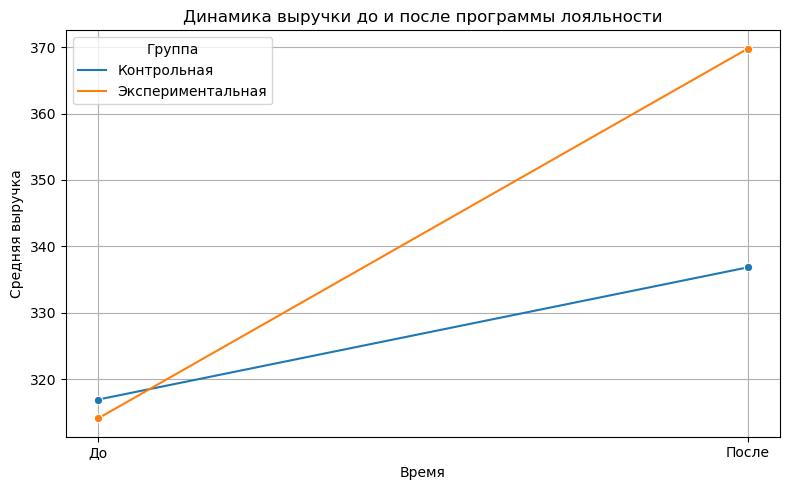

In [5]:
# Группировка и агрегация
df_grouped = df.groupby(['Новый_Маркетинг', 'После_Обновления'])['Выручка_Магазина'].mean().reset_index()

# Переименование для читаемости
df_grouped['Группа'] = df_grouped['Новый_Маркетинг'].map({0: 'Контрольная', 1: 'Экспериментальная'})
df_grouped['Время'] = df_grouped['После_Обновления'].map({0: 'До', 1: 'После'})

# Построение графика
plt.figure(figsize=(8, 5))
sns.lineplot(data=df_grouped, x='Время', y='Выручка_Магазина', hue='Группа', marker='o')
plt.title('Динамика выручки до и после программы лояльности')
plt.ylabel('Средняя выручка')
plt.xlabel('Время')
plt.grid(True)
plt.tight_layout()
plt.show()
